# 01. TabPFN-3·3.5의 열 → 행 → 행 ICL 구조

TabPFN-3(Prior Labs, *TabPFN-3: Technical Report*, arXiv 2605.13986, 2026)는 v2와 2.5가 쓰던 셀 단위 2방향 attention을 버리고, 표를 세 단계로 나눠 읽는 구조로 바꿨습니다. 먼저 열마다 값의 분포를 요약하고(열 단계), 행마다 셀들을 벡터 하나로 압축한 뒤(행 단계), 그 행 벡터들로 in-context learning을 합니다(행 ICL). TabICL(Qu et al., 2025)이 먼저 쓴 뼈대이고, 최근 나온 tabular foundation model(TFM) 여럿(TabICLv2, Causilo, TabAbax 등)도 이 형태입니다. TabPFN-3.5(*TabPFN-3.5: Technical Report*, arXiv 2609.17895, 2026)는 이 뼈대를 그대로 두고 폭을 넓히고 셀 encoder를 바꿨습니다.

이 노트북은 2.5 노트북의 과일 표를 세 단계에 하나씩 통과시키며, 각 단계가 무엇을 받아 무엇을 내는지 실제 값으로 따라갑니다. 코드는 `src/minipfn/models/column_row_transformer.py`(`ColumnRowTransformer`)이고, 3과 3.5는 같은 클래스에 설정만 다릅니다(`src/minipfn/recipes/tabpfn_v3.py`의 `ARCHITECTURES`). 이 저장소는 3.5 구조를 분류와 회귀를 한 모델로 같이 학습하는 multitask로 학습하므로, 마지막에 그 학습 설정도 봅니다. 비교 대상인 v2·2.5 구조는 [03_tabpfn_v2/01 셀 단위 표현과 2방향 attention](../03_tabpfn_v2/01_two_way_attention_primer.ipynb)과 [04_tabpfn_v2_5/01 v2에서 바뀐 구조 4가지](../04_tabpfn_v2_5/01_architecture_changes.ipynb)에서 다뤘습니다. v2부터 3.5까지의 차이는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 모았고, 이 노트북은 그 표의 2.5 → 3, 3 → 3.5 칸을 따라갑니다.

다루는 흐름:

1. 한눈에 보기 — 세 단계와 파라미터 수
2. 왜 바꿨나 — 계산이 어디에 드는가
3. 셀 encoder — 셀 3개 묶기와 정답 embedding
4. 열 단계 — inducing point로 열 요약하기
5. 행 단계 — CLS 토큰으로 행을 벡터 하나로
6. 행 ICL — 학습 행만 보는 24층과 QASSMax
7. 출력 — retrieval decoder
8. 구조가 보장하는 성질과 보장하지 않는 성질
9. TabPFN-3.5가 바꾼 것
10. 이 저장소의 3.5 학습 설정 — 분류·회귀를 한 모델로
11. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/05_tabpfn_v3/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import set_seed
from minipfn.models.column_row_transformer import (
    ColumnRowTransformer,
    ColumnRowTransformerConfig,
    FourierCellEncoder,
    ecdf_midrank,
    group_offsets,
)
from minipfn.recipes import tabpfn_v2
from minipfn.recipes.tabpfn_v3 import ARCHITECTURES, paper

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 한눈에 보기 — 세 단계와 파라미터 수

`ARCHITECTURES`에는 구조마다, task마다 모델 설정이 들어 있습니다. 3은 분류와 회귀가 같은 구조이고 출력층만 다릅니다. 3.5에는 분류·회귀를 한 모델로 내는 `multitask`가 더 있습니다.

In [3]:
rows = {}
for arch, by_task in ARCHITECTURES.items():
    for task, settings in by_task.items():
        rows[f"{arch} {task}"] = settings
display(pd.DataFrame(rows).T.drop(columns="model_type"))

,emsize,nlayers,nhead,features_per_group,n_inducing,n_cls,qk_norm,encoder,target_norm,head_mlp
v3 classification,128,24,8,3,128,4,False,linear,False,False
v3 regression,128,24,8,3,128,4,False,linear,False,False
v3.5 classification,128,24,16,3,128,8,True,fourier,True,True
v3.5 regression,128,24,16,3,128,8,True,fourier,True,True
v3.5 multitask,128,24,16,3,128,8,True,fourier,True,True


`emsize`(E = 128)는 셀·열·행 단계의 폭이고, `n_cls`는 행 하나를 압축할 CLS 토큰 수입니다. 행 ICL의 폭은 `n_cls × E`라서 3은 512, 3.5는 1,024입니다. `nlayers`와 `nhead`는 행 ICL의 층 수와 head 수입니다. 나머지 네 열(`qk_norm`, `encoder`, `target_norm`, `head_mlp`)은 3.5가 바꾼 것이라 9절에서 봅니다.

실제 크기의 모델을 만들어 파라미터를 단계별로 셉니다. 학습 설정 `paper(task, arch)`의 `build_model()`은 학습에 쓰는 모델과 같은 것을 만듭니다. 모델의 맨 앞 이름(`column_blocks`, `icl_layers` 등)을 단계로 묶습니다.

In [4]:
STAGE = {
    "cell_encoder": "셀 encoder",
    "cell_target": "셀 encoder",
    "cell_target_norm": "셀 encoder",
    "column_blocks": "열 단계",
    "cls_tokens": "행 단계",
    "row_blocks": "행 단계",
    "row_norm": "행 단계",
    "icl_target": "행 ICL",
    "icl_target_norm": "행 ICL",
    "icl_layers": "행 ICL",
    "icl_norm": "행 ICL",
    "pre_head": "출력",
    "heads": "출력",
}


def stage_counts(model):
    counts = {}
    for name, p in model.named_parameters():
        stage = STAGE[name.split(".")[0]]
        counts[stage] = counts.get(stage, 0) + p.numel()
    counts["합계"] = model.num_parameters()
    return counts


def split_counts(model, tasks=("classification", "regression")):
    # 9.3에서 쓴다: 이름에 task가 들어간 파라미터는 그 task 것, 나머지는 같이 쓰는 것
    counts = {"같이 쓰는 것": 0} | {t: 0 for t in tasks}
    for name, p in model.named_parameters():
        task = next((t for t in tasks if f".{t}." in f".{name}."), "같이 쓰는 것")
        counts[task] += p.numel()
    return counts


counts = {}
for arch, task in [("v3", "classification"), ("v3", "regression"), ("v3.5", "multitask")]:
    model = paper(task, arch).build_model()
    counts[f"{arch} {task}"] = stage_counts(model)
    if task == "multitask":
        full_split = split_counts(model)  # 219M 모델을 9.3에서 다시 만들지 않도록 여기서 센다
    del model

order = ["셀 encoder", "열 단계", "행 단계", "행 ICL", "출력", "합계"]
param_table = pd.DataFrame(counts).reindex(order).fillna(0).astype(int)
display(param_table.style.format("{:,}"))

v25 = tabpfn_v2.with_architecture(tabpfn_v2.paper("classification"), "v2.5").build_model()
print(f"비교: TabPFN-2.5 분류 모델 {v25.num_parameters():,}")

,v3 classification,v3 regression,v3.5 multitask
셀 encoder,"2,176","1,152","30,752"
열 단계,"869,616","869,616","869,808"
행 단계,"394,624","394,624","395,232"
행 ICL,"51,363,328","51,359,232","203,194,368"
출력,"427,392","5,650,312","14,336,264"
합계,"53,057,136","58,274,936","218,826,424"


비교: TabPFN-2.5 분류 모델 14,335,306


파라미터는 거의 다 행 ICL(24층)에 있습니다. 3 분류 모델에서 셀 encoder, 열 단계, 행 단계를 다 합쳐도 127만 개이고, 행 ICL이 5,136만 개입니다. 회귀 모델은 출력층이 bar distribution 구간 5,000개의 logit을 내느라 520만 개쯤 더 큽니다. 3.5는 행 ICL의 폭이 두 배(512 → 1,024)라 그 층들이 네 배가 되고, 전체가 2억 1,883만 개로 보고서의 "220M"과 비슷합니다. 3.5 multitask 모델은 분류와 회귀의 출력층을 둘 다 갖고 있어서 출력 쪽도 큽니다.

TabPFN-2.5 분류 모델(1,434만 개)과 비교하면 3은 파라미터가 4배 가까이 많습니다. 그런데 다음 절에서 보듯이 계산은 오히려 적습니다.

## 2. 왜 바꿨나 — 계산이 어디에 드는가

v2·2.5는 셀(묶음) 하나하나가 토큰이고, 층마다 두 방향으로 attention합니다. 행 $R$개, 학습 행 $N$개, 토큰 열 $C$개라고 하면 층 하나에서 다음을 계산합니다.

- feature attention: 행마다 토큰 $C$개가 서로를 봅니다. $R \cdot C^2$
- sample attention: 열마다 행 $R$개가 학습 행 $N$개를 봅니다. $C \cdot R \cdot N$

둘째 항이 문제입니다. 행 수와 열 수가 곱해져서 층마다 다시 계산되고, 2.5는 이것을 24층 반복합니다. 3은 행과 열의 상호작용을 앞쪽 몇 블록에서만 하고, 24층짜리 ICL은 행 벡터 하나씩만 다룹니다.

- 열 단계(3블록): 열마다 inducing point $M$개(128)가 학습 행을 요약하고 모든 행이 그 요약을 봅니다. $F \cdot M \cdot (N + R)$
- 행 단계(3블록): 행마다 CLS $k$개와 feature 토큰 $F$개가 서로를 봅니다. $R \cdot (k + F)^2$. 마지막 블록은 CLS만 query라 $R \cdot k \cdot (k + F)$입니다(5절)
- 행 ICL(24층): 행 $R$개가 학습 행 $N$개를 봅니다. $R \cdot N$. **feature 수와 상관없습니다**

attention 점수(query와 key의 내적)를 몇 번 계산하는지 세어 비교합니다. 폭(차원)과 MLP는 빼고 셉니다. 3은 셀 묶기가 토큰 수를 줄이지 않아서(3절) 토큰 열이 feature 수 $F$와 같고, 2.5는 $\lceil F/3 \rceil + 1$입니다(셀 3개 묶음 + y 토큰).

In [5]:
def scores_v25(rows, n_train, n_features, layers=24):
    c = -(-n_features // 3) + 1  # 셀 3개 묶음 + y 토큰
    feature_attention = rows * c * c
    sample_attention = c * rows * n_train
    return layers * (feature_attention + sample_attention)


def scores_v3(rows, n_train, n_features, m=128, k=4, column_blocks=3, row_blocks=3, layers=24):
    column = column_blocks * n_features * m * (n_train + rows)
    tokens = k + n_features
    # 마지막 블록은 CLS k개만 query (5절)
    row = (row_blocks - 1) * rows * tokens**2 + rows * k * tokens
    icl = layers * rows * n_train
    return {"열 단계": column, "행 단계": row, "행 ICL": icl}


cost = {}
for rows, n_features in [(1_000, 10), (1_000, 100), (10_000, 100), (100_000, 100), (10_000, 1_000)]:
    n_train = int(rows * 0.8)
    v3 = scores_v3(rows, n_train, n_features)
    cost[(rows, n_features)] = {
        "2.5 (억)": scores_v25(rows, n_train, n_features) / 1e8,
        "3 (억)": sum(v3.values()) / 1e8,
        "3 / 2.5": sum(v3.values()) / scores_v25(rows, n_train, n_features),
        "3 중 행 ICL 비중": v3["행 ICL"] / sum(v3.values()),
    }
cost_table = pd.DataFrame(cost).T.rename_axis(["행 수", "feature 수"])
display(cost_table.round(3))

2.5 (억)     3 (억)  3 / 2.5  3 중 행 ICL 비중
행 수    feature 수                                            
1000   10             0.966     0.266    0.275         0.723
       100            7.014     1.104    0.157         0.174
10000  100          674.940    28.317    0.042         0.678
100000 100        67229.400  2011.168    0.030         0.955
10000  1000        6701.340   290.325    0.043         0.066

행 1,000개, feature 10개인 작은 표에서도 3의 계산이 2.5의 4분의 1쯤이고, 행이 10만 개가 되면 30분의 1까지 줄어듭니다. 2.5의 sample attention은 $C \cdot R \cdot N$이라 행과 feature가 함께 늘면 곱으로 커지는데, 3에서 $R \cdot N$을 계산하는 행 ICL은 feature 수와 상관없기 때문입니다. 대신 3의 행 단계는 $(k + F)^2$이라 feature가 아주 많은 표(1,000개)에서는 행 ICL의 비중이 7%쯤으로 떨어지고 행 단계가 계산 대부분을 차지합니다. 그래도 3블록뿐이라 24층 내내 열 방향 attention을 하는 2.5보다 훨씬 적습니다.

실제 크기 모델의 forward 시간을 CPU에서 재 봅니다. 학습 행 80%, 테스트 행 20%인 분류 표이고, 세 번 재서 가운데 값을 씁니다.

In [6]:
def forward_seconds(model, x, y_train, repeat=3):
    with torch.inference_mode():
        model(x, y_train)  # 처음 한 번은 준비(캐시)로 빼고 잰다
        seconds = []
        for _ in range(repeat):
            start = time.perf_counter()
            model(x, y_train)
            seconds.append(time.perf_counter() - start)
    return float(np.median(seconds))  # 여러 번 재서 가운데 값


torch.manual_seed(0)
timing_models = {
    "2.5 (14M)": v25.eval(),
    "3 (53M)": paper("classification", "v3").build_model().eval(),
}
timing = {}
for rows, n_features in [(1024, 10), (1024, 100), (1024, 400), (4096, 100)]:
    n_train = int(rows * 0.8)
    x_big = torch.randn(1, rows, n_features)
    y_big = torch.randint(0, 2, (1, n_train)).float()
    seconds = {name: forward_seconds(m, x_big, y_big) for name, m in timing_models.items()}
    timing[(rows, n_features)] = seconds | {
        "비율 (3 / 2.5)": seconds["3 (53M)"] / seconds["2.5 (14M)"]
    }
display(pd.DataFrame(timing).T.rename_axis(["행 수", "feature 수"]).round(2))

2.5 (14M)  3 (53M)  비율 (3 / 2.5)
행 수  feature 수                                  
1024 10              0.31     0.22          0.71
     100             2.31     0.70          0.30
     400             9.88     3.22          0.33
4096 100            16.90     3.08          0.18

파라미터가 4배 가까이 많은 3이 feature 10개에서도 더 빠르고(0.7배), feature 100개에서는 3분의 1, 거기서 행을 4배로 늘리면 5분의 1로 줄어듭니다. 위의 점수 개수 표와 같은 방향입니다. CPU에서 잰 값이라 실행마다 조금씩 다르고 GPU와도 다를 수 있습니다. TabPFN-3 보고서는 feature 200개면 학습 행 100만 개, feature 2,000개면 10만 개까지 검증했다고 적었는데, 이 구조가 그 바탕입니다(이 저장소의 v3 권장 크기는 그 가운데 점인 10만 행·2,000 feature, `recipes/tabpfn_v3.py`의 `SUPPORTED_SIZE`). 이제 과일 표를 넣어 세 단계를 하나씩 따라갑니다.

## 3. 셀 encoder — 셀 3개 묶기와 정답 embedding

2.5 노트북과 같은 과일 표입니다. feature 5개, 학습 행 4개(사과 2, 배 2), 정답을 가린 테스트 행 2개입니다.

In [7]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "지름(cm)": [7.5, 7.2, 9.0, 8.6, 7.4, 8.8],
        "산도(pH)": [3.4, 3.5, 3.9, 3.8, 3.4, 3.9],
        "껍질(mm)": [0.6, 0.5, 1.0, 0.9, 0.6, 1.0],
    }
)
y = np.array([0, 0, 1, 1])  # 학습 행의 정답: 0 = 사과, 1 = 배
n_train = 4
roles = ["학습 1", "학습 2", "학습 3", "학습 4", "테스트 5", "테스트 6"]

shown = fruit.copy()
shown["y"] = ["0 (사과)", "0 (사과)", "1 (배)", "1 (배)", "?", "?"]
shown.index = roles
display(shown)

,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm),y
학습 1,210,13.5,7.5,3.4,0.6,0 (사과)
학습 2,190,14.0,7.2,3.5,0.5,0 (사과)
학습 3,320,11.0,9.0,3.9,1.0,1 (배)
학습 4,290,11.5,8.6,3.8,0.9,1 (배)
테스트 5,200,13.0,7.4,3.4,0.6,?
테스트 6,310,12.0,8.8,3.9,1.0,?


**1단계: 열마다 표준화합니다.** v2·2.5와 같습니다. 평균과 표준편차는 학습 행 4개에서만 구하고, 모델 안(`standardize_cells`)에서 계산하므로 입력에는 원래 값을 넣습니다.

In [8]:
features = fruit.to_numpy(dtype=float)
mean = features[:n_train].mean(axis=0)
std = features[:n_train].std(axis=0)  # 모델과 같이 n으로 나눈 표준편차
z = (features - mean) / std

display(pd.DataFrame(z, columns=fruit.columns, index=roles).round(2))

,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm)
학습 1,-0.79,0.78,-0.77,-1.21,-0.73
학습 2,-1.16,1.18,-1.17,-0.73,-1.21
학습 3,1.25,-1.18,1.24,1.21,1.21
학습 4,0.69,-0.78,0.70,0.73,0.73
테스트 5,-0.97,0.39,-0.90,-1.21,-0.73
테스트 6,1.06,-0.39,0.97,1.21,1.21


**2단계: feature마다 토큰 하나를 만들고, 거기에 다른 열 2개를 함께 묶습니다.** 2.5는 이웃한 열 3개를 잘라 묶음 하나로 만들었습니다(feature 5개 → 묶음 2개). 3도 셀 3개를 토큰 하나에 넣지만 방식이 다릅니다. feature $j$의 토큰에 열 $j$, $j+1$, $j+3$의 셀을 넣고, 열 번호는 끝에서 처음으로 돌아갑니다(mod $C$). 그래서 토큰 수는 feature 수와 같고(5개), 열마다 토큰이 하나씩 생기며, 셀 하나는 토큰 3개에 들어갑니다. 열 번호에 더하는 offset은 보고서의 0, 1, 3이고, 이 저장소는 그것을 $2^j - 1$로 일반화했습니다(`group_offsets`).

In [9]:
offsets = group_offsets(3)
print("offset:", offsets)

names = list(fruit.columns)
n_features = len(names)
grouping = {}
for j in range(n_features):
    members = [names[(j + o) % n_features] for o in offsets]
    grouping[f"토큰 {j + 1} ({names[j]})"] = members
display(pd.DataFrame(grouping, index=["칸 1", "칸 2", "칸 3"]).T)

offset: (0, 1, 3)


,칸 1,칸 2,칸 3
토큰 1 (무게(g)),무게(g),당도(brix),산도(pH)
토큰 2 (당도(brix)),당도(brix),지름(cm),껍질(mm)
토큰 3 (지름(cm)),지름(cm),산도(pH),무게(g)
토큰 4 (산도(pH)),산도(pH),껍질(mm),당도(brix)
토큰 5 (껍질(mm)),껍질(mm),무게(g),지름(cm)


'산도' 토큰에는 산도, 껍질, 그리고 처음으로 돌아가 '당도'가 들어갑니다. 열마다 토큰이 있으니 4절의 열 단계에서 "열마다 요약한다"가 그대로 성립하고, 각 토큰은 처음부터 다른 열 두 개의 값을 함께 봅니다.

**3단계: 토큰마다 [값 3개, 결측 표시 3개]를 Linear 하나에 넣어 E차원 벡터로 만듭니다.** 결측 표시는 v2처럼 결측값이면 $-2$, 아니면 $0$이고, 결측 칸의 값은 0입니다. 손 계산이 실제 모델과 같은지 작은 모델로 확인합니다. 작은 `ColumnRowTransformer`를 만들고, 셀 encoder(`cell_encoder`)에 들어가는 텐서를 hook으로 꺼냅니다.

In [10]:
TINY = dict(
    emsize=16,
    n_inducing=4,
    column_blocks=1,
    column_heads=2,
    n_cls=2,
    row_blocks=2,
    row_heads=2,
    nlayers=2,
    nhead=2,
    decoder_heads=2,
    decoder_head_dim=8,
    qassmax_hidden=8,
    n_out=3,
)


def fill_zero_weights(model, std=0.3):
    # 0으로 시작한 가중치(attention 출력 투영, MLP 마지막 Linear 등)를 무작위 값으로 채운다
    with torch.no_grad():
        for p in model.parameters():
            if p.dim() > 1 and (p == 0).all():
                nn.init.normal_(p, std=std)
    return model


torch.manual_seed(0)
tiny = fill_zero_weights(ColumnRowTransformer(ColumnRowTransformerConfig(**TINY))).eval()

x = torch.tensor(features, dtype=torch.float32)[None]  # (데이터셋 1, 행 6, feature 5)
y_train = torch.tensor(y, dtype=torch.float32)[None]  # (데이터셋 1, 학습 행 4)

captured = {}
hooks = [
    tiny.cell_encoder.register_forward_hook(
        lambda module, inputs, output: captured.update(encoder_in=inputs[0], encoder_out=output)
    ),
    tiny.column_blocks[0].register_forward_pre_hook(
        lambda module, inputs: captured.update(column_in=inputs[0])
    ),
]
with torch.no_grad():
    logits = tiny(x, y_train)
for hook in hooks:
    hook.remove()

encoder_in = captured["encoder_in"][0, 0]  # 첫 학습 행: (토큰 5, 값 3 + 결측 표시 3)
expected = np.stack([z[0, [(j + o) % n_features for o in offsets]] for j in range(n_features)])
print(
    "encoder 입력:",
    tuple(captured["encoder_in"].shape),
    " (데이터셋, 행, 토큰, 값 3 + 결측 표시 3)",
)
print("encoder 출력:", tuple(captured["encoder_out"].shape), " (데이터셋, 행, 토큰, E)")
print("값 3칸이 손 계산과 같음:", np.allclose(encoder_in[:, :3].numpy(), expected, atol=1e-5))
print("결측 표시 3칸이 모두 0:", not encoder_in[:, 3:].any().item())

encoder 입력: (1, 6, 5, 6)  (데이터셋, 행, 토큰, 값 3 + 결측 표시 3)
encoder 출력: (1, 6, 5, 16)  (데이터셋, 행, 토큰, E)
값 3칸이 손 계산과 같음: True
결측 표시 3칸이 모두 0: True


**4단계: 학습 행의 토큰에 정답 embedding을 더합니다.** v2·2.5는 정답 y를 따로 토큰 하나로 붙였는데, 3은 학습 행의 모든 셀 토큰에 그 행 정답의 embedding을 더합니다. 분류는 클래스마다 벡터 하나(`nn.Embedding`)이고 처음 값을 서로 직교하게 둡니다. 회귀는 `Linear(1 → E)`입니다. 테스트 행은 정답을 모르니 아무것도 더하지 않습니다.

hook으로 꺼낸 두 텐서, 곧 셀 encoder 출력과 열 단계에 들어가는 입력의 차이를 행마다 봅니다. 열 단계 입력은 (데이터셋 × 열, 행, E) 모양으로 바뀌어 있으므로 다시 맞춰 뺍니다.

In [11]:
cells_out = captured["encoder_out"][0]  # (행 6, 토큰 5, E)
column_in = (
    captured["column_in"].view(n_features, len(roles), -1).transpose(0, 1)
)  # (행 6, 토큰 5, E)
added = column_in - cells_out  # 행마다 더해진 것
class_vectors = tiny.cell_target["classification"].encode.weight.detach()  # (클래스 3, E)

added_rows = {}
for i, role in enumerate(roles):
    vector = added[i, 0]  # 첫 토큰에 더해진 것 (모든 토큰에 같다)
    row = {
        "더한 벡터의 크기": vector.norm().item(),
        "토큰끼리 같음": torch.allclose(added[i], vector.expand_as(added[i]), atol=1e-6),
    }
    for c in range(2):
        row[f"클래스 {c} 벡터와 같음"] = torch.allclose(vector, class_vectors[c], atol=1e-6)
    added_rows[role] = row
display(pd.DataFrame(added_rows).T)

gram = (class_vectors @ class_vectors.T).numpy()
display(
    pd.DataFrame(
        gram,
        index=["클래스 0", "클래스 1", "클래스 2"],
        columns=["클래스 0", "클래스 1", "클래스 2"],
    ).round(3)
)

,더한 벡터의 크기,토큰끼리 같음,클래스 0 벡터와 같음,클래스 1 벡터와 같음
학습 1,1.0,True,True,False
학습 2,1.0,True,True,False
학습 3,1.0,True,False,True
학습 4,1.0,True,False,True
테스트 5,0.0,True,False,False
테스트 6,0.0,True,False,False


,클래스 0,클래스 1,클래스 2
클래스 0,1.0,0.0,0.0
클래스 1,0.0,1.0,0.0
클래스 2,0.0,0.0,1.0


사과인 학습 1·2에는 클래스 0 벡터가, 배인 학습 3·4에는 클래스 1 벡터가 모든 토큰에 똑같이 더해졌고, 테스트 행에는 아무것도 더해지지 않았습니다. 아래 표는 클래스 벡터끼리의 내적입니다. 처음 값이 직교라 대각선 밖이 0입니다. 학습 전에는 클래스끼리 헷갈리지 않는 방향에서 시작한다는 뜻입니다.

정답 embedding은 6절의 행 ICL 입력에도 한 번 더, 다른 encoder로 더합니다. 셀 단계의 정답은 열 단계와 행 단계가 "이 값이 어느 클래스 행의 값인지"를 알게 하고, 행 ICL의 정답은 행 벡터 단위의 in-context learning에 쓰입니다.

## 4. 열 단계 — inducing point로 열 요약하기

열 단계는 열마다 따로 돕니다. 모양으로 보면 (데이터셋 × 열, 행, E)이고, 같은 열의 토큰끼리만 정보를 주고받습니다. v2·2.5의 sample attention처럼 모든 행이 학습 행을 직접 보면 열마다 $R \cdot N$을 계산해야 합니다. 3은 그 사이에 학습되는 벡터 $M$개(inducing point, 128개)를 둡니다(Set Transformer의 ISAB).

1. **요약**: inducing point $M$개가 query가 되어 학습 행 $N$개를 봅니다. 결과는 "이 열의 학습 행 값이 어떻게 분포하는가"를 담은 벡터 $M$개입니다.
2. **펼치기**: 모든 행(학습·테스트)이 query가 되어 요약 $M$개를 봅니다.

열마다 계산은 $M \cdot N + R \cdot M$으로, 행 수에 비례합니다. 무게 열 하나와 inducing point 2개로 손 계산을 해 봅니다. 토큰 대신 표준화한 무게 값 하나로 줄이고, inducing point A는 무거운 행에, B는 가벼운 행에 높은 점수를 주도록 정합니다(점수 = $\pm 2 \times$ z값). 실제 모델에서는 이 점수가 학습으로 정해집니다.

In [12]:
weight_z = z[:, 0]  # 무게 열의 표준화한 값 (행 6개)
grams = features[:, 0]
inducing_sign = {"inducing A (heavy)": 2.0, "inducing B (light)": -2.0}


def softmax(scores):
    e = np.exp(scores - scores.max())
    return e / e.sum()


summary_rows, summaries = {}, {}
for name, sign in inducing_sign.items():
    scores = sign * weight_z[:n_train]  # 학습 행 4개에만 점수를 준다 (테스트 행은 보지 않는다)
    weights = softmax(scores)
    summaries[name] = weights @ grams[:n_train]  # 요약 = 학습 행 무게의 가중 평균
    summary_rows[name] = dict(zip(roles[:n_train], weights, strict=True)) | {
        "요약 (가중 평균 g)": summaries[name]
    }
display(pd.DataFrame(summary_rows).T.round(2))

,학습 1,학습 2,학습 3,학습 4,요약 (가중 평균 g)
inducing A (heavy),0.01,0.01,0.74,0.24,310.54
inducing B (light),0.32,0.66,0.01,0.02,198.65


A는 배(320g, 290g)에 가중치를 몰아 요약이 310g쯤 되고, B는 사과(210g, 190g) 쪽으로 몰려 200g 가까이 됩니다. 학습 행 무게의 분포를 "무거운 무리"와 "가벼운 무리" 두 숫자로 요약한 셈입니다. 테스트 행은 요약에 들어가지 않습니다.

펼치기에서는 모든 행이 이 두 요약을 봅니다. 행의 점수를 요약과 가까울수록 크게(점수 = $-|$무게 − 요약$| / 20$) 정해 보면 다음과 같습니다.

In [13]:
summary_values = np.array(list(summaries.values()))
broadcast_rows = {}
for i, role in enumerate(roles):
    scores = -np.abs(grams[i] - summary_values) / 20  # 요약과 가까울수록 큰 점수
    weights = softmax(scores)
    broadcast_rows[f"{role} ({grams[i]:.0f}g)"] = dict(zip(inducing_sign, weights, strict=True))
display(pd.DataFrame(broadcast_rows).T.round(2))

,inducing A (heavy),inducing B (light)
학습 1 (210g),0.01,0.99
학습 2 (190g),0.00,1.00
학습 3 (320g),1.00,0.00
학습 4 (290g),0.97,0.03
테스트 5 (200g),0.00,1.00
테스트 6 (310g),1.00,0.00


200g인 테스트 5는 B(가벼운 무리)를, 310g인 테스트 6은 A(무거운 무리)를 거의 다 가져옵니다. 테스트 행은 학습 행을 하나하나 보지 않고도 "내 무게는 이 열의 어느 쪽인가"를 알게 됩니다. 요약은 학습 행에서만 만들었으므로, 테스트 행끼리는 서로 영향을 주지 않습니다.

누가 누구를 보는지 표로 정리합니다. 행은 attend하는 쪽, 열은 attend받는 쪽이고 1이면 attend합니다.

In [14]:
m = 2
ind_names = [f"inducing {chr(65 + i)}" for i in range(m)]
summarize = pd.DataFrame(0, index=ind_names, columns=roles)
summarize.loc[:, roles[:n_train]] = 1  # inducing point → 학습 행
broadcast = pd.DataFrame(1, index=roles, columns=ind_names)  # 모든 행 → inducing point
print("① 요약: inducing point가 학습 행을 본다")
display(summarize)
print("② 펼치기: 모든 행이 inducing point를 본다")
display(broadcast)

① 요약: inducing point가 학습 행을 본다


,학습 1,학습 2,학습 3,학습 4,테스트 5,테스트 6
inducing A,1,1,1,1,0,0
inducing B,1,1,1,1,0,0


② 펼치기: 모든 행이 inducing point를 본다


,inducing A,inducing B
학습 1,1,1
학습 2,1,1
학습 3,1,1
학습 4,1,1
테스트 5,1,1
테스트 6,1,1


실제 모델에서는 이 두 attention 뒤에 각각 MLP가 붙고(`InducedBlock`), 이것을 3블록 반복합니다. 요약 쪽 attention에는 6절의 QASSMax를 써서 학습 행 수가 바뀌어도 요약이 흐려지지 않게 합니다. 토큰 모양은 열 단계에 들어가기 전과 같습니다.

In [15]:
captured = {}
hook = tiny.column_blocks[-1].register_forward_hook(
    lambda module, inputs, output: captured.update(column_out=output)
)
with torch.no_grad():
    tiny(x, y_train)
hook.remove()
print("열 단계 출력:", tuple(captured["column_out"].shape), " (데이터셋 × 열 5, 행 6, E)")
print(
    "inducing point:",
    tuple(tiny.column_blocks[0].inducing.shape),
    " (M, E) — 모든 열·데이터셋이 같이 쓰는 학습 파라미터",
)

열 단계 출력: (5, 6, 16)  (데이터셋 × 열 5, 행 6, E)
inducing point: (4, 16)  (M, E) — 모든 열·데이터셋이 같이 쓰는 학습 파라미터


## 5. 행 단계 — CLS 토큰으로 행을 벡터 하나로

열 단계를 지난 토큰은 이제 "이 행의 이 열 값이 열 전체에서 어디쯤인가"를 압니다. 행 단계는 행마다 따로 돌며, 그 행의 feature 토큰 $F$개 앞에 학습되는 CLS 토큰 $k$개(3은 4개)를 붙여 서로 attention합니다. 모양은 (데이터셋 × 행, $k + F$, E)입니다. 첫 학습 행의 토큰 줄은 이렇습니다.

In [16]:
k = 4  # TabPFN-3의 CLS 수
sequence = [f"CLS {i + 1}" for i in range(k)] + names
display(
    pd.DataFrame({"토큰": sequence, "RoPE 위치": range(len(sequence))}).set_index("RoPE 위치").T
)

RoPE 위치,0,1,2,3,4,5,6,7,8
토큰,CLS 1,CLS 2,CLS 3,CLS 4,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm)


세 가지를 봅니다.

- **RoPE(base $10^5$)로 위치를 넣습니다.** CLS가 0~3번, feature가 4번부터 열 순서대로입니다. 그래서 이 단계는 feature 순서에 따라 결과가 달라집니다(8절에서 확인).
- **마지막 블록은 CLS만 query입니다.** 다음 단계에서 쓰는 것은 CLS 출력뿐이라, feature 토큰의 출력은 계산하지 않습니다.
- **CLS 출력 $k$개를 이어 붙여 행 벡터 하나로 만듭니다.** 3은 $4 \times 128 = 512$차원입니다.

이 단계가 끝나면 feature 수가 텐서 모양에서 사라집니다. feature가 5개든 2,000개든 행 하나는 512차원 벡터 하나이고, 2절에서 본 대로 24층짜리 행 ICL의 계산이 feature 수와 상관없어지는 지점이 여기입니다. 작은 모델(CLS 2개, E = 16)로 모양을 확인합니다.

In [17]:
captured = {}
hooks = [
    tiny.row_blocks[0].register_forward_pre_hook(
        lambda module, inputs: captured.update(row_in=inputs[0])
    ),
    tiny.row_blocks[-1].register_forward_hook(
        lambda module, inputs, output: captured.update(row_last=output)
    ),
    tiny.icl_layers[0].register_forward_pre_hook(
        lambda module, inputs: captured.update(icl_in=inputs[0])
    ),
]
with torch.no_grad():
    tiny(x, y_train)
for hook in hooks:
    hook.remove()
print(
    "행 단계 입력:      ",
    tuple(captured["row_in"].shape),
    " (데이터셋 × 행 6, CLS 2 + feature 5, E)",
)
print(
    "마지막 블록 출력:  ",
    tuple(captured["row_last"].shape),
    " (데이터셋 × 행 6, CLS 2, E) — CLS만 남는다",
)
print("행 ICL 입력:       ", tuple(captured["icl_in"].shape), " (데이터셋, 행 6, CLS 2 × E)")

행 단계 입력:       (6, 7, 16)  (데이터셋 × 행 6, CLS 2 + feature 5, E)
마지막 블록 출력:   (6, 2, 16)  (데이터셋 × 행 6, CLS 2, E) — CLS만 남는다
행 ICL 입력:        (1, 6, 32)  (데이터셋, 행 6, CLS 2 × E)


3의 실제 설정이면 마지막 줄이 (데이터셋, 행, 512)이고, 3.5는 CLS가 8개라 1,024입니다.

이 저장소가 정한 것이 하나 있습니다. 실제 모델은 대부분의 attention 출력층을 0으로 시작하는데(처음에는 잔차에 아무것도 더하지 않게), 행 단계만은 0으로 시작하지 않습니다. CLS 토큰은 attention으로만 그 행의 셀 정보를 받으므로, 0에서 시작하면 학습 초기에 모든 행 벡터가 같아지고 gradient가 거의 0(1e-8)이었습니다.

## 6. 행 ICL — 학습 행만 보는 24층과 QASSMax

행 벡터에 정답 embedding을 한 번 더 더합니다(3절 4단계와 다른 encoder이고 폭이 행 벡터 폭). 그 뒤 24층 Transformer가 행을 토큰으로 in-context learning을 합니다. attention 규칙은 v1의 행 Transformer와 같습니다. 학습 행은 학습 행끼리, 테스트 행은 학습 행만 봅니다.

In [18]:
allowed = np.zeros((len(roles), len(roles)), dtype=int)
allowed[:, :n_train] = 1  # 모든 행 → 학습 행
display(pd.DataFrame(allowed, index=roles, columns=roles))

,학습 1,학습 2,학습 3,학습 4,테스트 5,테스트 6
학습 1,1,1,1,1,0,0
학습 2,1,1,1,1,0,0
학습 3,1,1,1,1,0,0
학습 4,1,1,1,1,0,0
테스트 5,1,1,1,1,0,0
테스트 6,1,1,1,1,0,0


테스트 행에는 한 가지가 더 있습니다. 학습 행은 head 8개가 각자 key·value를 쓰지만, 테스트 행은 query head 8개가 모두 첫 head의 key·value 하나만 봅니다(multi-query attention). 테스트 행이 볼 key·value를 head마다 따로 들고 있지 않아도 되므로, 학습 행이 많을 때 추론 메모리가 줄어듭니다. 학습 행끼리의 attention은 그대로 head마다 따로입니다.

### 6.1 QASSMax — 행이 많아져도 attention이 흐려지지 않게

softmax에는 key가 많아질수록 가중치가 흐려지는 성질이 있습니다. 테스트 행 하나가 학습 행 $n$개를 보는데, 그중 딱 하나만 닮아서 점수가 4이고 나머지는 0이라고 합시다. 닮은 행이 받는 가중치는 $e^4 / (e^4 + n - 1)$입니다. 학습 행이 10개일 때는 대부분을 가져오지만, 1,000개만 되어도 0.05로 떨어집니다. 닮은 행이 하나뿐인데도 나머지 999개의 평균에 묻히는 것입니다.

scalable softmax는 query에 $s \cdot \log n$을 곱해 이것을 막습니다. 점수가 $4 \cdot s \log n$이 되니 가중치는 $n^{4s} / (n^{4s} + n - 1)$이고, $4s > 1$이면 $n$이 커질수록 오히려 1에 가까워집니다. $s = 0.5$로 두고 비교합니다.

,배율 s·log n,softmax,scalable softmax
학습 행 수 n,,,
10,1.151,0.858,0.917
100,2.303,0.355,0.990
1000,3.454,0.052,0.999
10000,4.605,0.005,1.000
100000,5.756,0.001,1.000
1000000,6.908,0.000,1.000


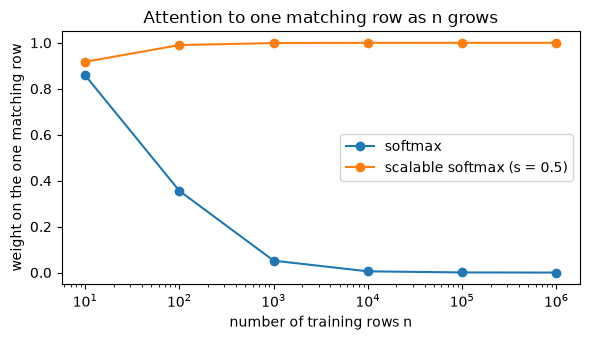

In [19]:
MATCH_SCORE, S = 4.0, 0.5
ssmax_rows = {}
for n in [10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    plain = math.exp(MATCH_SCORE) / (math.exp(MATCH_SCORE) + n - 1)
    scaled_score = MATCH_SCORE * S * math.log(n)
    scaled = math.exp(scaled_score) / (math.exp(scaled_score) + n - 1)
    ssmax_rows[n] = {"배율 s·log n": S * math.log(n), "softmax": plain, "scalable softmax": scaled}
ssmax_table = pd.DataFrame(ssmax_rows).T.rename_axis("학습 행 수 n")
display(ssmax_table.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ssmax_table.index, ssmax_table["softmax"], marker="o", label="softmax")
ax.plot(
    ssmax_table.index,
    ssmax_table["scalable softmax"],
    marker="o",
    label="scalable softmax (s = 0.5)",
)
ax.set_xscale("log")
ax.set_xlabel("number of training rows n")
ax.set_ylabel("weight on the one matching row")
ax.set_title("Attention to one matching row as n grows")
ax.legend()
plt.tight_layout()
plt.show()

TabPFN-3의 QASSMax(query-aware scalable softmax)는 이 배율을 학습합니다. 식은 $q \leftarrow q \cdot \text{base\_mlp}(\log n) \cdot (1 + \tanh(\text{query\_mlp}(q)))$입니다. $\text{base\_mlp}$는 $\log n$을 받아 head와 차원마다 배율을 내고(위의 $s \log n$을 학습하는 것), $\text{query\_mlp}$는 query마다 그 배율을 조금씩 조절합니다. $\text{query\_mlp}$의 마지막 층은 0으로 시작해서 처음에는 조절이 없습니다. 이 식은 보고서에는 없고 공개된 추론 코드(PriorLabs/TabPFN v9의 `architectures/tabpfn_v3*.py`, Apache 2.0)에서 확인했습니다. 이 저장소는 그 설계만 보고 코드와 가중치는 가져오지 않았습니다.

쓰는 곳은 key 수가 데이터셋마다 달라지는 attention입니다. 열 단계의 요약(inducing point → 학습 행), 행 ICL 24층, 7절의 retrieval decoder입니다. key가 늘 inducing point 128개인 열 단계의 펼치기, key가 행 하나의 토큰뿐인 행 단계에는 쓰지 않습니다. 이 저장소의 학습은 학습 행 2,048개까지의 표로 하는데(10절) 추론은 그보다 훨씬 긴 표에도 하려면, key 수가 학습 때보다 훨씬 많아져도 attention이 버텨야 합니다. QASSMax가 그 역할을 합니다.

## 7. 출력 — retrieval decoder

회귀는 v2와 같은 bar distribution입니다. 테스트 행 벡터를 구간 5,000개의 logit으로 바꿉니다(3은 2층 MLP, 3.5는 잔차 MLP 뒤 Linear 하나).

분류는 방식이 바뀌었습니다. v2·2.5는 테스트 행 벡터를 Linear에 넣어 클래스 10개의 logit을 냈습니다. 3의 retrieval decoder는 이렇게 합니다.

1. 테스트 행이 query, 학습 행이 key가 되어 attention 가중치를 냅니다.
2. 그 가중치로 학습 행의 one-hot 정답을 평균해 클래스 확률 $p$를 만듭니다.
3. logit은 $\log(\max(p, 10^{-5}) + 3 \times 10^{-5})$입니다.
4. 이것을 head 6개로 따로 하고 확률을 평균합니다.

"닮은 학습 행의 정답을 투표로 모은다"는 것이라, 클래스 수에 매인 파라미터가 없습니다. 테스트 5 하나와 head 하나로 손 계산을 해 봅니다. 테스트 5(200g, 사과처럼 생긴 행)의 점수를 학습 행마다 정해 둡니다.

In [20]:
scores = np.array([2.0, 1.5, -1.0, -0.5])  # 테스트 5 → 학습 1~4 (사과 둘과 더 닮았다)
weights = softmax(scores)
onehot = np.eye(3)[y]  # 학습 행 정답의 one-hot (클래스 3개 자리)
p = weights @ onehot
logit = np.log(np.maximum(p, 1e-5) + 3e-5)

display(pd.DataFrame({"attention 가중치": weights, "정답": y}, index=roles[:n_train]).round(3))
display(
    pd.DataFrame(
        {"확률 p": p, "logit": logit},
        index=["클래스 0 (사과)", "클래스 1 (배)", "클래스 2 (학습 행에 없음)"],
    ).round(3)
)

,attention 가중치,정답
학습 1,0.575,0
학습 2,0.349,0
학습 3,0.029,1
학습 4,0.047,1


,확률 p,logit
클래스 0 (사과),0.924,-0.079
클래스 1 (배),0.076,-2.578
클래스 2 (학습 행에 없음),0.000,-10.127


사과인 학습 1·2에 가중치 0.92가 몰려 클래스 0의 확률이 0.92가 됩니다. 학습 행에 없는 클래스 2는 확률이 정확히 0이고, logit은 $\log(10^{-5} + 3 \times 10^{-5}) \approx -10.1$로 바닥에 깔립니다. $10^{-5}$로 자르는 것은 확률이 0인 클래스의 log가 $-\infty$가 되지 않게 하는 것입니다.

실제 모델로 확인합니다. 정답 embedding 수(`n_out`, 클래스 상한)를 10으로 둔 작은 모델에 학습 행 정답이 0과 1뿐인 과일 표를 넣으면, 클래스 2~9의 logit이 모두 그 바닥값이어야 합니다.

In [21]:
torch.manual_seed(0)
ten_class = fill_zero_weights(
    ColumnRowTransformer(ColumnRowTransformerConfig(**(TINY | {"n_out": 10})))
).eval()
with torch.no_grad():
    out = ten_class(x, y_train)

print("출력:", tuple(out.shape), " (데이터셋, 테스트 행 2, 클래스 상한 10)")
floor = math.log(4e-5)  # 확률이 0인 클래스의 logit 바닥값
print(f"클래스 2~9의 logit: {out[0, :, 2:].unique().tolist()} (바닥값 log(4e-5) = {floor:.3f})")
display(
    pd.DataFrame(
        out[0, :, :3].numpy(), index=roles[n_train:], columns=["클래스 0", "클래스 1", "클래스 2"]
    ).round(3)
)

출력: (1, 2, 10)  (데이터셋, 테스트 행 2, 클래스 상한 10)
클래스 2~9의 logit: [-10.126630783081055] (바닥값 log(4e-5) = -10.127)


,클래스 0,클래스 1,클래스 2
테스트 5,-0.682,-0.705,-10.127
테스트 6,-0.688,-0.698,-10.127


학습 행에 나온 클래스만 확률을 받고, 나오지 않은 클래스는 모두 같은 바닥값입니다. 출력층이 클래스마다 가중치를 갖지 않으므로, 클래스 상한은 3절의 정답 embedding 수 하나로만 정해집니다. 보고서는 이 decoder로 클래스 160개까지 다룬다고 적었고, 클래스가 많은 데이터셋에서 1위라고 보고한 것도 이 decoder 덕분으로 보입니다. 이 저장소는 prior가 만드는 클래스 수 상한(10)을 `n_out`으로 씁니다.

## 8. 구조가 보장하는 성질과 보장하지 않는 성질

v2 primer에서 본 성질을 3 구조로 다시 확인합니다. 무작위 표(학습 행 20개, 테스트 행 6개, feature 5개)로 다음 세 가지를 바꿔 logit이 얼마나 달라지는지 봅니다.

- **학습 행 순서**: 열 단계의 요약도, 행 ICL도 학습 행을 집합으로 봅니다(위치 정보가 없음). 같아야 합니다.
- **테스트 행을 하나씩 따로 넣기**: 테스트 행은 어느 단계에서도 다른 테스트 행을 보지 않습니다. 같아야 합니다.
- **feature 순서**: 셀 묶기(열 $j$, $j+1$, $j+3$)와 행 단계의 RoPE가 열 순서에 달려 있습니다. 달라질 수 있습니다.

In [22]:
def predict(model, x_train, y_tr, x_test):
    with torch.no_grad():
        return model(torch.cat([x_train, x_test], dim=1), y_tr)


def max_diff(a, b):
    return f"{(a - b).abs().max().item():.1e}"


torch.manual_seed(1)
x_tr, y_tr = torch.randn(1, 20, 5), torch.randint(0, 3, (1, 20)).float()
x_te = torch.randn(1, 6, 5)

base = predict(tiny, x_tr, y_tr, x_te)
row_perm = torch.randperm(20)
one_by_one = torch.cat([predict(tiny, x_tr, y_tr, x_te[:, j : j + 1]) for j in range(6)], dim=1)
feature_perm = torch.tensor([2, 0, 4, 1, 3])

display(
    pd.DataFrame(
        {
            "바꾼 것": ["학습 행 순서", "테스트 행을 하나씩 따로 넣기", "feature 순서"],
            "logit 최대 차이": [
                max_diff(base, predict(tiny, x_tr[:, row_perm], y_tr[:, row_perm], x_te)),
                max_diff(base, one_by_one),
                max_diff(
                    base, predict(tiny, x_tr[:, :, feature_perm], y_tr, x_te[:, :, feature_perm])
                ),
            ],
        }
    )
)

,바꾼 것,logit 최대 차이
0,학습 행 순서,1.2e-07
1,테스트 행을 하나씩 따로 넣기,1.8e-07
2,feature 순서,2.1e-03


앞의 둘은 float 반올림 오차 수준이고, feature 순서를 바꾸면 예측이 달라집니다. 열 이름에는 순서가 없으니 모델이 열 순서에 기대면 곤란합니다. 그래서 추론 때 앙상블 멤버마다 열 순서를 무작위로 섞고(`minipfn/inference/preprocessing.py`의 `self.order`), 멤버들의 예측을 평균해 순서 효과를 지웁니다. 3.5의 추론 설정은 멤버 8개입니다(`recipes/tabpfn_v3.py`의 `INFERENCE`).

## 9. TabPFN-3.5가 바꾼 것

3.5 보고서는 세 단계 뼈대를 그대로 두고 아래를 바꿨습니다. 보고서에 없는 것(정답 LayerNorm, 출력층 앞 MLP)은 공개 추론 코드에서 확인했습니다.

In [23]:
v3, v35 = ARCHITECTURES["v3"]["classification"], ARCHITECTURES["v3.5"]["classification"]
changed = {name: {"v3": v3[name], "v3.5": v35[name]} for name in v3 if v3[name] != v35[name]}
meaning = {
    "n_cls": "CLS 수 (행 벡터 폭 = n_cls × 128)",
    "nhead": "행 ICL head 수 (head dim 64 그대로)",
    "qk_norm": "attention의 q·k에 RMSNorm",
    "encoder": "셀 encoder (9.1)",
    "target_norm": "정답 embedding 뒤 LayerNorm",
    "head_mlp": "출력층 앞 task별 잔차 MLP",
}
display(pd.DataFrame(changed).T.assign(뜻=lambda t: t.index.map(meaning)))

,v3,v3.5,뜻
nhead,8,16,행 ICL head 수 (head dim 64 그대로)
n_cls,4,8,CLS 수 (행 벡터 폭 = n_cls × 128)
qk_norm,False,True,attention의 q·k에 RMSNorm
encoder,linear,fourier,셀 encoder (9.1)
target_norm,False,True,정답 embedding 뒤 LayerNorm
head_mlp,False,True,출력층 앞 task별 잔차 MLP


파라미터가 4배로 는 것은 거의 다 둘째 줄(`n_cls`) 때문입니다. 첫 줄의 head 수는 head 폭을 64로 두고 폭을 나누는 개수만 바꾸므로 파라미터 수와는 상관이 거의 없습니다. CLS가 4개에서 8개가 되어 행 벡터 폭이 512에서 1,024로 두 배가 되면, 행 ICL 층의 파라미터는 폭의 제곱에 비례하니 네 배가 됩니다(1절 표의 행 ICL 5,136만 → 2억 319만). 3.5 보고서는 층 수를 적지 않아서 3의 24층을 그대로 두었고, 그러면 보고서의 220M과 비슷해집니다.

### 9.1 셀 encoder: Linear → Fourier + ECDF

3의 셀 encoder는 [값 3개, 결측 표시 3개]를 받는 Linear 하나였습니다. 3.5는 두 갈래를 더하고 LayerNorm합니다.

- **Fourier 항**: z값에 학습되는 주파수 32개를 곱해 sin·cos을 만들고 Linear합니다. 주파수의 처음 값(0.1~10, log 간격)은 이 저장소가 정했습니다.
- **메타 항**: [z값, 결측 표시, ECDF 조화 항]을 Linear합니다. ECDF 조화 항은 열 안에서 그 값의 순위 $u$로 만든 $\sin(\pi k u)$, $\cos(\pi k u)$($k = 1..4$)입니다.

순위 $u$는 학습 행에 대한 midrank입니다. (나보다 작은 학습 값 수 + 나와 같은 학습 값 수 / 2) / 학습 행 수입니다. 무게 열로 손 계산합니다. 학습 행의 무게는 190, 210, 290, 320입니다.

In [24]:
train_grams = np.sort(grams[:n_train])
midrank_rows = {}
for i, role in enumerate(roles):
    smaller = int((train_grams < grams[i]).sum())
    equal = int((train_grams == grams[i]).sum())
    midrank_rows[role] = {
        "무게(g)": grams[i],
        "작은 수": smaller,
        "같은 수": equal,
        "u (손 계산)": (smaller + equal / 2) / n_train,
    }
midrank_table = pd.DataFrame(midrank_rows).T

u_model = ecdf_midrank(torch.tensor(features, dtype=torch.float32)[None], n_train)[0, :, 0]
midrank_table["u (모델)"] = u_model.numpy()
display(midrank_table.round(3))

,무게(g),작은 수,같은 수,u (손 계산),u (모델)
학습 1,210.0,1.0,1.0,0.375,0.375
학습 2,190.0,0.0,1.0,0.125,0.125
학습 3,320.0,3.0,1.0,0.875,0.875
학습 4,290.0,2.0,1.0,0.625,0.625
테스트 5,200.0,1.0,0.0,0.250,0.250
테스트 6,310.0,3.0,0.0,0.750,0.750


학습 1(210g)은 자기보다 작은 학습 값이 1개, 같은 값이 1개(자기 자신)라 $u = (1 + 0.5)/4 = 0.375$입니다. 테스트 5(200g)는 190g과 210g 사이라 작은 값 1개, 같은 값 0개로 $u = 0.25$입니다. 모델의 `ecdf_midrank`도 같은 값을 냅니다.

z값은 평균과 표준편차로만 정규화하므로 값 하나가 아주 크면(이상치) 나머지가 좁은 곳에 몰립니다. 순위 $u$는 이상치가 있어도 늘 0~1에 고르게 퍼집니다. 3까지는 추론 때 quantile 변환한 앙상블 멤버를 따로 만들어 비슷한 효과를 냈습니다. 3.5는 추론 전처리에서 quantile·robust·SVD를 빼고 standard 하나만 쓰는데(`INFERENCE["v3.5"]`), encoder가 순위를 직접 보게 된 것과 맞물린 변화로 보입니다.

Fourier 항은 값에 따라 꺾이는 표현을 처음부터 만들 수 있게 합니다. 셀 묶음의 첫 칸 z값만 $-3$에서 $3$까지 바꾸고 나머지는 0으로 둔 채, 두 encoder가 만드는 토큰의 앞 세 차원을 그립니다. 학습하지 않은 무작위 가중치입니다.

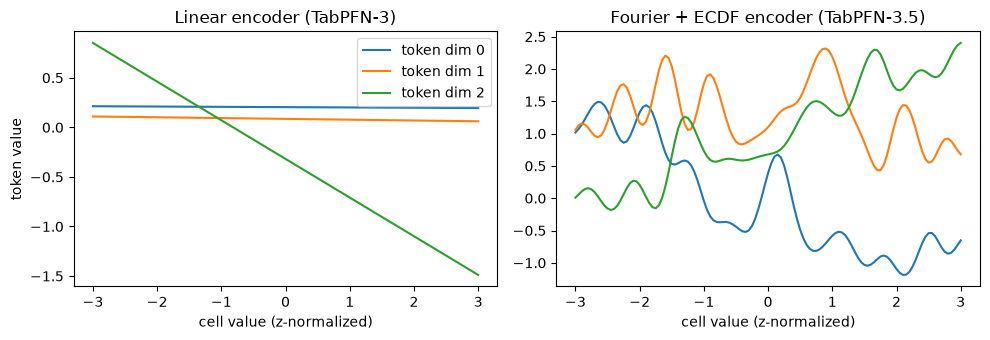

In [25]:
torch.manual_seed(0)
E_small = 16
linear_encoder = nn.Linear(2 * 3, E_small)  # 3: [값 3개, 결측 표시 3개]
fourier_encoder = FourierCellEncoder(3, E_small)  # 3.5

sweep = torch.linspace(-3, 3, 121)
values_in = torch.zeros(len(sweep), 3)
values_in[:, 0] = sweep  # 첫 칸 z값만 바꾼다
indicator_in = torch.zeros(len(sweep), 3)
u_in = torch.full((len(sweep), 3), 0.5)
u_in[:, 0] = torch.distributions.Normal(0, 1).cdf(sweep)  # 정규분포 열이라고 보고 순위를 정한다

with torch.no_grad():
    tokens = {
        "Linear encoder (TabPFN-3)": linear_encoder(torch.cat([values_in, indicator_in], dim=-1)),
        "Fourier + ECDF encoder (TabPFN-3.5)": fourier_encoder(
            values_in[None, None], indicator_in[None, None], u_in[None, None]
        )[0, 0],
    }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, (title, out) in zip(axes, tokens.items(), strict=True):
    for d in range(3):
        ax.plot(sweep, out[:, d], label=f"token dim {d}")
    ax.set_title(title)
    ax.set_xlabel("cell value (z-normalized)")
axes[0].set_ylabel("token value")
axes[0].legend()
plt.tight_layout()
plt.show()

Linear encoder의 토큰은 셀 값에 대해 직선이라, 값에 따라 꺾이는 표현은 뒤의 층들이 만들어야 합니다. Fourier encoder는 주파수가 다른 sin·cos이 섞여 값에 따라 여러 번 꺾입니다. `FourierCellEncoder` 하나의 파라미터는 2만 9천 개쯤이라 모델 전체에 비하면 아주 작습니다(1절 표의 3.5 '셀 encoder' 30,752개는 여기에 셀 단계 정답 embedding과 그 LayerNorm을 더한 수입니다).

### 9.2 나머지 셋

- **`qk_norm`**: attention의 q와 k를 head 차원마다 RMSNorm합니다. q·k의 크기가 묶이니 attention logit이 끝없이 커지지 않습니다. v2 회귀를 학습할 때 logit이 수십만까지 커져 QK-clip으로 상한을 뒀는데, 이 구조에서는 QK-clip이 logit을 묶지 못합니다. QASSMax가 q에 입력에 따라 달라지는 배율을 곱하고, 테스트 행은 다른 head의 key를 보기 때문입니다. 그래서 이 저장소는 3·3.5 모두 QK-clip을 끄고(`with_architecture`), logit을 묶는 일은 3.5의 `qk_norm`에 맡깁니다.
- **`target_norm`**: 정답 embedding 뒤 LayerNorm입니다(셀 단계·행 ICL 각각). 분류의 클래스 벡터와 회귀의 `Linear(y)`는 크기가 다를 수 있는데, 두 task가 이 LayerNorm을 같이 써서 정답 신호의 크기를 task와 상관없이 맞춥니다.
- **`head_mlp`**: 출력층 앞에 task마다 잔차 MLP 하나를 둡니다. 마지막 층이 0으로 시작해 처음에는 아무것도 하지 않습니다.

### 9.3 분류·회귀를 한 모델로 (`multitask`)

3은 task마다 checkpoint가 따로였습니다(분류 53M, 회귀 58M). 3.5는 checkpoint 하나가 둘 다 하고, forward에 `task`를 줍니다. 공개 추론 코드에서 확인한 바로는 task마다 따로인 것은 정답 encoder(셀·ICL)와 출력층(앞 MLP 포함)뿐이고, 셀 encoder부터 행 ICL까지 나머지는 같이 씁니다. 작은 multitask 모델로 확인합니다.

In [26]:
torch.manual_seed(0)
multi_config = ColumnRowTransformerConfig(
    **(
        TINY
        | {
            "task": "multitask",
            "n_buckets": 50,
            "encoder": "fourier",
            "qk_norm": True,
            "target_norm": True,
            "head_mlp": True,
        }
    )
)
multi = fill_zero_weights(ColumnRowTransformer(multi_config)).eval()

y_class = torch.tensor(y, dtype=torch.float32)[None]  # 분류 정답: 사과 0, 배 1
y_sugar = torch.tensor(z[:n_train, 1], dtype=torch.float32)[None]  # 회귀 정답: 당도(표준화)
with torch.no_grad():
    out_class = multi(x, y_class, task="classification")
    out_reg = multi(x, y_sugar, task="regression")
print("분류 출력:", tuple(out_class.shape), " (데이터셋, 테스트 행, 클래스 상한)")
print("회귀 출력:", tuple(out_reg.shape), " (데이터셋, 테스트 행, bar 구간 수)")

# 1절에서 만든 split_counts로 센다. 실제 크기는 1절에서 센 full_split
display(
    pd.DataFrame({"작은 모델": split_counts(multi), "3.5 실제 크기": full_split})
    .rename(index={"classification": "분류만", "regression": "회귀만"})
    .style.format("{:,}")
)

분류 출력: (1, 2, 3)  (데이터셋, 테스트 행, 클래스 상한)
회귀 출력: (1, 2, 50)  (데이터셋, 테스트 행, bar 구간 수)


,작은 모델,3.5 실제 크기
같이 쓰는 것,"30,352","204,476,336"
분류만,"5,632","5,027,456"
회귀만,"5,874","9,322,632"


같은 모델이 `task`에 따라 클래스 logit과 bar 구간 logit을 냅니다. 실제 크기로는 2억 448만 개를 같이 쓰고, task마다 따로인 것은 분류 500만 개, 회귀 930만 개쯤입니다. 회귀 쪽이 큰 것은 구간 5,000개를 내는 출력층 때문입니다.

이름에 task가 들어가지 않는 `cell_target_norm`·`icl_target_norm`도 같이 쓰는 쪽에 들어갑니다. 위의 `target_norm`이 두 task 공용이라는 것과 같은 말입니다.

## 10. 이 저장소의 3.5 학습 설정 — 분류·회귀를 한 모델로

3.5 보고서는 학습 설정(step, 학습률, batch, task를 섞는 비율, 손실 가중치)을 하나도 공개하지 않았습니다. 이 저장소는 v2 논문 설정에서 시작하고 구조만 3.5로 바꿉니다(`recipes/tabpfn_v3.py`의 `paper`). 학습은 v2와 같은 `scripts/tabpfn_v2/train.py`이고, AI Runtime 설정은 `scripts/tabpfn_v3/train.yaml`(기본값 `TABPFN_V2_ARCH=v3.5`, `TABPFN_V2_TASK=multitask`)입니다.

In [27]:
train_config = paper("multitask", "v3.5")
shown_fields = {
    "task": "분류·회귀를 한 모델로",
    "model_type": "column_row_transformer",
    "prior_type": "학습 데이터 (TabICL 계열 graph SCM, v2·2.5와 같다)",
    "steps": "학습률 스케줄 전체 길이",
    "batch_size": "step마다 데이터셋 수",
    "lr": "최대 학습률",
    "warmup_steps": "warmup",
    "max_train_rows": "학습 표의 학습 행 수 상한",
    "max_features": "학습 표의 feature 수 상한",
    "qk_clip": "QK-clip (이 구조에서는 끈다)",
    "rewind_lr_factor": "학습이 무너져 되돌릴 때 학습률 배율",
}
display(
    pd.DataFrame(
        {"값": [getattr(train_config, f) for f in shown_fields], "뜻": list(shown_fields.values())},
        index=list(shown_fields),
    )
)

,값,뜻
task,multitask,분류·회귀를 한 모델로
model_type,column_row_transformer,column_row_transformer
prior_type,graph_scm,"학습 데이터 (TabICL 계열 graph SCM, v2·2.5와 같다)"
steps,2000000,학습률 스케줄 전체 길이
batch_size,64,step마다 데이터셋 수
lr,0.0002,최대 학습률
warmup_steps,10000,warmup
max_train_rows,2048,학습 표의 학습 행 수 상한
max_features,160,학습 표의 feature 수 상한
qk_clip,None,QK-clip (이 구조에서는 끈다)


학습 루프(`minipfn/training/loop.py`)가 multitask에서 다르게 하는 것은 네 가지입니다.

1. **task마다 prior가 따로입니다.** `task_configs()`가 설정을 분류용과 회귀용 둘로 나누고, 각자 prior와 데이터 로더를 만듭니다. 회귀의 bar 구간 경계도 회귀 prior로 정합니다. GPU당 prior 생성 worker는 두 task가 나눠 써서 CPU 사용량은 한 task 학습과 같습니다.
2. **step마다 task를 번갈아 씁니다.** `task = config.tasks[step % 2]`라서 짝수 step은 분류, 홀수 step은 회귀입니다. 모든 GPU가 같은 step에 같은 task를 씁니다. 비율 1:1은 이 저장소가 정한 것입니다.
3. **DDP가 쓰지 않은 파라미터를 허용합니다.** 분류 step에서는 회귀 출력층에 gradient가 없으므로 `find_unused_parameters=True`로 둡니다.
4. **검증은 task마다 따로 하고**, 지표 이름 뒤에 task를 붙입니다(`val_loss_classification`, `val_loss_regression`). `val_loss`는 두 손실의 평균이고, 학습이 무너졌는지 판단할 때 이것을 봅니다.

처음 몇 step이 어느 task를 쓰는지 봅니다.

In [28]:
display(
    pd.DataFrame(
        {
            "step": range(6),
            "task": [train_config.tasks[s % len(train_config.tasks)] for s in range(6)],
        }
    )
    .set_index("step")
    .T
)

step,0,1,2,3,4,5
task,classification,regression,classification,regression,classification,regression


학습이 무너졌을 때 되돌리는 규칙은 v2 회귀의 것(되돌릴 때 학습률 절반, `rewind_lr_factor = 0.5`)을 씁니다. v2를 학습할 때 회귀가 분류보다 자주 무너졌기 때문이고, 이것도 이 저장소가 정했습니다. 실행은 다음과 같습니다(실험 경로는 `.env.local`의 `MLFLOW_EXPERIMENT_DIR`).

```bash
databricks air run -f scripts/tabpfn_v3/train.yaml --watch \
  --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR
```

기본값은 8×H100에서 step 시간을 재는 짧은 실행(300 step)이고, 논문 규모 학습은 `TABPFN_V2_CONFIG_NAME=paper`, 학습률 스케줄 전체 길이(`TABPFN_V2_STEPS`), chunk 끝 step(`TABPFN_V2_STOP_STEP`)을 override로 줍니다. yaml의 `TABPFN_V2_STEPS`는 기본이 300이라, 이것을 빼면 `paper` 설정의 2,000,000 step 대신 300 step짜리 스케줄로 학습합니다. 자세한 옵션은 yaml 맨 위의 주석에 있습니다.

## 11. 정리

| 단계 | 하는 일 | 모양 | 보고서에 있는 것 | 공개 코드에서 확인한 것 | 여기서 정한 것 |
|---|---|---|---|---|---|
| 셀 encoder | 셀 3개(열 $j$, $j+1$, $j+3$)를 토큰 하나로, 학습 행에 정답 embedding | (B, R, F, 128) | 묶음 3, offset 0·1·3, E 128 | 정답 embedding을 셀 단계와 행 ICL 두 곳에 | offset을 $2^j - 1$로 일반화 |
| 열 단계 | inducing point 128개가 학습 행을 요약, 모든 행이 요약을 봄 (×3) | (B·F, R, 128) | inducing 128, 3블록 | QASSMax는 요약 쪽에만 | — |
| 행 단계 | CLS $k$개 + feature 토큰, RoPE, CLS 출력을 이어 붙임 (×3) | (B·R, k+F, 128) → (B, R, 128k) | CLS 4, RoPE base $10^5$ | 마지막 블록은 CLS만 query | attention 출력층을 0으로 시작하지 않음 |
| 행 ICL | 학습 행끼리, 테스트 행 → 학습 행 (×24), QASSMax | (B, R, 512) | 24층, 테스트 행 KV head 1 | QASSMax 식 | — |
| 출력 | 분류 retrieval decoder, 회귀 bar distribution 5,000 | (B, T, 클래스 또는 구간) | 최대 160클래스 | logit $\log(\max(p, 10^{-5}) + 3 \times 10^{-5})$ | 클래스 상한 = prior 상한 10 |
| 3.5 | CLS 8(폭 1,024), head 16, q·k RMSNorm, Fourier + ECDF encoder, 분류·회귀 한 모델 | (B, R, 1024) | 220M, 폭·head·encoder | 정답 LayerNorm, 출력층 앞 MLP, task별 부품 | 층 수 24, 주파수 처음 값, task 1:1 번갈아 학습, v2 학습 설정 |

v2·2.5는 셀 토큰이 24층 내내 행과 열 두 방향을 오갔고, 3은 그 일을 앞쪽 몇 블록(열 3 + 행 3)에서 끝낸 뒤 행 벡터 하나로 ICL을 합니다. 파라미터는 늘었지만(14M → 53M) 계산은 feature 수와 행 수가 클수록 오히려 줄고, 그래서 보고서는 feature 200개면 학습 행 100만 개, 2,000개면 10만 개까지 다룰 수 있다고 적었습니다. 대신 셀 묶기와 RoPE 때문에 feature 순서에 따라 결과가 달라지므로, 추론 때 열 순서를 섞은 앙상블로 그 효과를 지웁니다.

v2·2.5와 나란히 놓은 전체 비교는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 있습니다.

3.5 multitask 학습 결과(분류·회귀를 한 모델로 학습했을 때 benchmark에서 task마다 따로 학습한 모델과 견주어 어떤지)는 학습이 끝난 뒤 이 폴더에 노트북을 더해 정리합니다.